# Machine Learning: Breast Cancer Relapse Prediction

This notebook develops and evaluates machine-learning models to investigate whether gene-expression profiles can predict breast cancer relapse using the GSE2034 dataset.

The analysis will include baseline comparison, feature selection, model training, cross-validation, and performance evaluation.

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/dashboard_dataset.csv")

# Display dataset dimensions
print("Dataset dimensions:", df.shape)

# Preview the data
df.head()

Dataset dimensions: (286, 11134)


,Sample_Accession,1007_s_at,1053_at,117_at,121_at,1294_at,1316_at,1405_i_at,1487_at,1494_f_at,...,AFFX-r2-Hs18SrRNA-3_s_at,AFFX-r2-Hs18SrRNA-5_at,AFFX-r2-Hs18SrRNA-M_x_at,AFFX-r2-Hs28SrRNA-3_at,AFFX-r2-Hs28SrRNA-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,Relapse,Follow_up_months,ER_status
0,GSM36777,10.656269,6.293524,6.785154,8.147451,8.116105,5.543389,6.297705,7.425518,10.121389,...,8.400972,8.037748,7.410176,8.773551,6.837441,13.203729,12.855004,0,79,ER+
1,GSM36778,10.826179,6.105409,6.446397,8.757778,8.046588,5.858173,6.626540,7.458408,6.841101,...,7.721659,6.983152,7.174253,8.256445,6.706327,13.493307,13.060972,1,50,ER+
2,GSM36779,11.126097,6.239484,6.779564,8.530315,8.072878,5.518387,5.466980,7.596806,11.131859,...,9.984656,9.969394,9.311195,10.067197,8.430180,13.838555,13.578604,0,132,ER+
3,GSM36780,10.477855,6.628975,6.673216,8.499970,7.719168,5.735773,7.427322,7.726948,6.511897,...,8.643687,7.821658,7.371878,8.287202,6.714380,13.537538,13.089998,0,84,ER-
4,GSM36781,10.582677,6.699766,6.682278,8.374228,7.990972,5.629806,9.247610,7.865347,6.683223,...,6.770322,6.333042,5.762516,6.332495,5.918873,13.457076,13.013675,0,147,ER+


## 1. Define the prediction target and features

The target variable is Relapse, which indicates whether a patient experienced relapse (1) or did not experience relapse (0).

Gene-expression measurements will be used as predictors. Clinical variables and sample identifiers will be excluded from this initial model.

In [2]:
# Define target variable
y = df["Relapse"]

# Remove target and non-gene-expression columns from predictors
exclude_columns = [
    "Relapse",
    "ER_status",
    "Sample_Accession",
    "Follow_up_months",
    "Unnamed: 0"
]

X = df.drop(columns=exclude_columns, errors="ignore")

# Inspect dimensions
print("Predictor matrix:", X.shape)
print("Target variable:", y.shape)

# Check target distribution
print("\nRelapse distribution:")
print(y.value_counts())

print("\nRelapse proportions:")
print(y.value_counts(normalize=True))

Predictor matrix: (286, 11130)
Target variable: (286,)

Relapse distribution:
Relapse
0    179
1    107
Name: count, dtype: int64

Relapse proportions:
Relapse
0    0.625874
1    0.374126
Name: proportion, dtype: float64


## 2. Baseline Model (benchmark)

A majority-class classifier will be used as a baseline to establish the minimum predictive performance that a machine-learning model should improve upon.

The classifier predicts the majority outcome for every sample, without using gene-expression information. This dummyclassifier is using the same stratified 5-fold cross validation the rest of the predictive models will use as well, to generate a fair comparison.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Create baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Fit and predict
baseline.fit(X, y)
baseline_predictions = baseline.predict(X)

# Evaluate baseline
print("Baseline Accuracy:", accuracy_score(y, baseline_predictions))
print("Baseline Balanced Accuracy:", balanced_accuracy_score(y, baseline_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y, baseline_predictions))

print("\nClassification Report:")
print(classification_report(y, baseline_predictions, zero_division=0))

Baseline Accuracy: 0.6258741258741258
Baseline Balanced Accuracy: 0.5

Confusion Matrix:
[[179   0]
 [107   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77       179
           1       0.00      0.00      0.00       107

    accuracy                           0.63       286
   macro avg       0.31      0.50      0.38       286
weighted avg       0.39      0.63      0.48       286



## 3. Model Validation Strategy

Stratified nested 5-fold cross-validation will be used to evaluate model performance and optimize hyperparameters.

The outer 5-fold loop will estimate generalization performance, while the inner 5-fold loop will optimize model hyperparameters and feature selection.

All preprocessing, scaling, and feature selection will occur within the cross-validation pipeline to prevent data leakage.

The models that will be compared: 
* baseline majority class dummy classifier
* Linear SVM
* RBF-SVM
* Random Forest
* Regularized logistic regression with elastic net penalty, or lasso logistic regression.

#### Evaluation
All of the models will be compared using the same metrics: ROC-AUC, PR-AUC, balanced accuracy, specificity and sensitivity. Since this dataset is looking to predict relapse, I am particularly interested in the ROC-AUC, balanced accuracy and sensitivity. Reason being: missing a relapse case (false negative) would be much more detrimental to a patient than labeling someone as a relapse risk when they are not (false positive).

In [4]:
# Import modelling tools

#Linear SVM Classifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    recall_score,
    average_precision_score,
    confusion_matrix
)

# Confirm predictors are numeric
X = X.apply(pd.to_numeric, errors="raise")

# Check for missing and infinite values
print("Missing values:", X.isna().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

# Define the modelling pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", class_weight="balanced"))
])

# Hyperparameter search space
param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "svm__C": [0.01, 0.1, 1, 10]
}

# Define outer and inner cross-validation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store results
fold_results = []

# Nested cross-validation
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Inner loop: hyperparameter optimization
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    # Evaluate on untouched outer test fold
    best_model = search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.decision_function(X_test)

    # Calculate metrics
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Selected Features": search.best_params_["feature_selection__k"],
        "Best C": search.best_params_["svm__C"]
    })

    print(f"Completed fold {fold}/5")
    print("Best parameters:", search.best_params_)

# Display fold results
results_df = pd.DataFrame(fold_results)

display(results_df)

# Summarize performance
print("\nNested Cross-Validation Results")

for metric in [
    "ROC-AUC",
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity",
    "PR-AUC"
]:
    print(
        f"{metric}: "
        f"{results_df[metric].mean():.3f} "
        f"+/- {results_df[metric].std():.3f}"
    )

Missing values: 0
Infinite values: 0
Completed fold 1/5
Best parameters: {'feature_selection__k': 500, 'svm__C': 0.1}
Completed fold 2/5
Best parameters: {'feature_selection__k': 100, 'svm__C': 0.01}
Completed fold 3/5
Best parameters: {'feature_selection__k': 25, 'svm__C': 0.1}
Completed fold 4/5
Best parameters: {'feature_selection__k': 25, 'svm__C': 10}
Completed fold 5/5
Best parameters: {'feature_selection__k': 50, 'svm__C': 0.01}


,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,Selected Features,Best C
0,1,0.714646,0.638889,0.500000,0.777778,0.599216,500,0.10
1,2,0.653439,0.646825,0.571429,0.722222,0.529602,100,0.01
2,3,0.596561,0.601190,0.619048,0.583333,0.433667,25,0.10
3,4,0.541005,0.525794,0.523810,0.527778,0.372998,25,10.00
4,5,0.640260,0.558442,0.545455,0.571429,0.569865,50,0.01



Nested Cross-Validation Results
ROC-AUC: 0.629 +/- 0.065
Balanced Accuracy: 0.594 +/- 0.052
Sensitivity: 0.552 +/- 0.046
Specificity: 0.637 +/- 0.107
PR-AUC: 0.501 +/- 0.095


In [5]:
#Evaluating the DummyClassifier using the nested cross validation, to establish a baseline for performance comparison

from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

baseline_results = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)

    predictions = baseline.predict(X_test)
    probabilities = baseline.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    baseline_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)

print("\nMean baseline performance:")
display(baseline_df.drop(columns="Fold").mean().to_frame("Mean"))

,Fold,Accuracy,Balanced Accuracy,Sensitivity,Specificity,ROC-AUC,PR-AUC
0,1,0.620690,0.5,0.0,1.0,0.5,0.379310
1,2,0.631579,0.5,0.0,1.0,0.5,0.368421
2,3,0.631579,0.5,0.0,1.0,0.5,0.368421
3,4,0.631579,0.5,0.0,1.0,0.5,0.368421
4,5,0.614035,0.5,0.0,1.0,0.5,0.385965



Mean baseline performance:


,Mean
Accuracy,0.625892
Balanced Accuracy,0.500000
Sensitivity,0.000000
Specificity,1.000000
ROC-AUC,0.500000
PR-AUC,0.374108


In [6]:
#RBF-SVM Classifier

rbf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

rbf_param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "svm__C": [0.01, 0.1, 1, 10],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1]
}

rbf_fold_results = []
rbf_selected_genes = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    rbf_search = GridSearchCV(
        estimator=rbf_pipeline,
        param_grid=rbf_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    rbf_search.fit(X_train, y_train)

    best_model = rbf_search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.decision_function(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    selected_indices = best_model.named_steps[
        "feature_selection"
    ].get_support(indices=True)

    selected_gene_names = X.columns[selected_indices].tolist()
    rbf_selected_genes.append(selected_gene_names)

    rbf_fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Selected Features": len(selected_gene_names),
        "Best C": rbf_search.best_params_["svm__C"],
        "Best Gamma": rbf_search.best_params_["svm__gamma"]
    })

rbf_results_df = pd.DataFrame(rbf_fold_results)

display(rbf_results_df.round(3))

,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,Selected Features,Best C,Best Gamma
0,1,0.795,0.658,0.455,0.861,0.669,500,10,0.001
1,2,0.679,0.534,0.429,0.639,0.592,500,1,0.001
2,3,0.557,0.542,0.333,0.750,0.566,500,10,scale
3,4,0.702,0.647,0.571,0.722,0.576,500,10,0.001
4,5,0.634,0.669,0.682,0.657,0.508,50,10,scale


In [7]:
# Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Define Random Forest pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("rf", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameter search space
rf_param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "rf__n_estimators": [200, 500],
    "rf__max_depth": [None, 5, 10],
    "rf__min_samples_leaf": [1, 3, 5]
}

# Store results
rf_fold_results = []

# Nested cross-validation
for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Inner loop: hyperparameter optimization
    rf_search = GridSearchCV(
        estimator=rf_pipeline,
        param_grid=rf_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    rf_search.fit(X_train, y_train)

    # Evaluate on untouched outer test fold
    best_rf = rf_search.best_estimator_

    predictions = best_rf.predict(X_test)
    probabilities = best_rf.predict_proba(X_test)[:, 1]

    # Calculate confusion matrix metrics
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    rf_fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Sensitivity": recall_score(
            y_test, predictions, pos_label=1
        ),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        ),
        "Selected Features": rf_search.best_params_[
            "feature_selection__k"
        ],
        "Best Parameters": rf_search.best_params_
    })

    print(f"Completed fold {fold}/5")
    print("Best parameters:", rf_search.best_params_)

# Display results
rf_results_df = pd.DataFrame(rf_fold_results)

display(rf_results_df.drop(columns="Best Parameters"))

# Summarize performance
print("\nRandom Forest Nested Cross-Validation Results")

for metric in [
    "ROC-AUC",
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity",
    "PR-AUC"
]:
    print(
        f"{metric}: "
        f"{rf_results_df[metric].mean():.3f} "
        f"+/- {rf_results_df[metric].std():.3f}"
    )

Completed fold 1/5
Best parameters: {'feature_selection__k': 500, 'rf__max_depth': 10, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 500}
Completed fold 2/5
Best parameters: {'feature_selection__k': 500, 'rf__max_depth': 10, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 500}
Completed fold 3/5
Best parameters: {'feature_selection__k': 25, 'rf__max_depth': 5, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 200}
Completed fold 4/5
Best parameters: {'feature_selection__k': 50, 'rf__max_depth': 5, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 500}
Completed fold 5/5
Best parameters: {'feature_selection__k': 250, 'rf__max_depth': 5, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 500}


,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,Selected Features
0,1,0.691919,0.684343,0.590909,0.777778,0.566708,500
1,2,0.658730,0.585317,0.476190,0.694444,0.565483,500
2,3,0.518519,0.468254,0.380952,0.555556,0.381021,25
3,4,0.555556,0.482143,0.380952,0.583333,0.397576,50
4,5,0.707792,0.706494,0.727273,0.685714,0.624995,250



Random Forest Nested Cross-Validation Results
ROC-AUC: 0.627 +/- 0.085
Balanced Accuracy: 0.585 +/- 0.110
Sensitivity: 0.511 +/- 0.148
Specificity: 0.659 +/- 0.090
PR-AUC: 0.507 +/- 0.110


### Copilots Recommendation
Testing out Copilots recommendation (as required by the AI Productivity Declaration). Copilot recommended a regularized logistic regression with elastic net penalty, or lasso logistic regression.

In [8]:
from sklearn.linear_model import LogisticRegression

elastic_net_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    ))
])

elastic_net_param_grid = {
    "feature_selection__k": [25, 50, 100, 250, 500],
    "model__C": [0.001, 0.01, 0.1, 1, 10],
    "model__l1_ratio": [0, 0.25, 0.5, 0.75, 1]
}

elastic_net_fold_results = []
elastic_net_selected_genes = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    elastic_net_search = GridSearchCV(
        estimator=elastic_net_pipeline,
        param_grid=elastic_net_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    elastic_net_search.fit(X_train, y_train)

    best_model = elastic_net_search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    # Identify genes retained by ANOVA
    selected_indices = best_model.named_steps[
        "feature_selection"
    ].get_support(indices=True)

    selected_gene_names = X.columns[selected_indices].tolist()
    elastic_net_selected_genes.append(selected_gene_names)

    # Identify genes with non-zero logistic regression coefficients
    coefficients = best_model.named_steps["model"].coef_[0]

    nonzero_genes = [
        gene for gene, coefficient in zip(
            selected_gene_names, coefficients
        )
        if not np.isclose(coefficient, 0)
    ]

    elastic_net_fold_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(y_test, predictions, pos_label=1),
        "Specificity": tn / (tn + fp),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ANOVA Features": len(selected_gene_names),
        "Nonzero Coefficients": len(nonzero_genes),
        "Best C": elastic_net_search.best_params_["model__C"],
        "Best L1 Ratio": elastic_net_search.best_params_["model__l1_ratio"]
    })

elastic_net_results_df = pd.DataFrame(elastic_net_fold_results)

display(elastic_net_results_df.round(3))

c:\Users\Sara\Documents\CIND820\gse2034-research-dashboard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Sara\Documents\CIND820\gse2034-research-dashboard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=Non

,Fold,ROC-AUC,Balanced Accuracy,Sensitivity,Specificity,PR-AUC,ANOVA Features,Nonzero Coefficients,Best C,Best L1 Ratio
0,1,0.742,0.707,0.636,0.778,0.627,500,178,1.00,0.50
1,2,0.656,0.633,0.571,0.694,0.547,500,44,0.10,1.00
2,3,0.610,0.550,0.571,0.528,0.444,25,12,0.10,0.75
3,4,0.668,0.581,0.524,0.639,0.558,500,48,0.10,1.00
4,5,0.686,0.555,0.682,0.429,0.625,50,19,0.01,0.25


,Baseline,Linear SVM,RBF SVM,Random Forest,Logistic Regression (Ridge)
ROC-AUC,0.500,0.629,0.673,0.627,0.672
Balanced Accuracy,0.500,0.594,0.610,0.585,0.605
Sensitivity,0.000,0.552,0.494,0.511,0.597
Specificity,1.000,0.637,0.726,0.659,0.613
PR-AUC,0.374,0.501,0.582,0.507,0.560


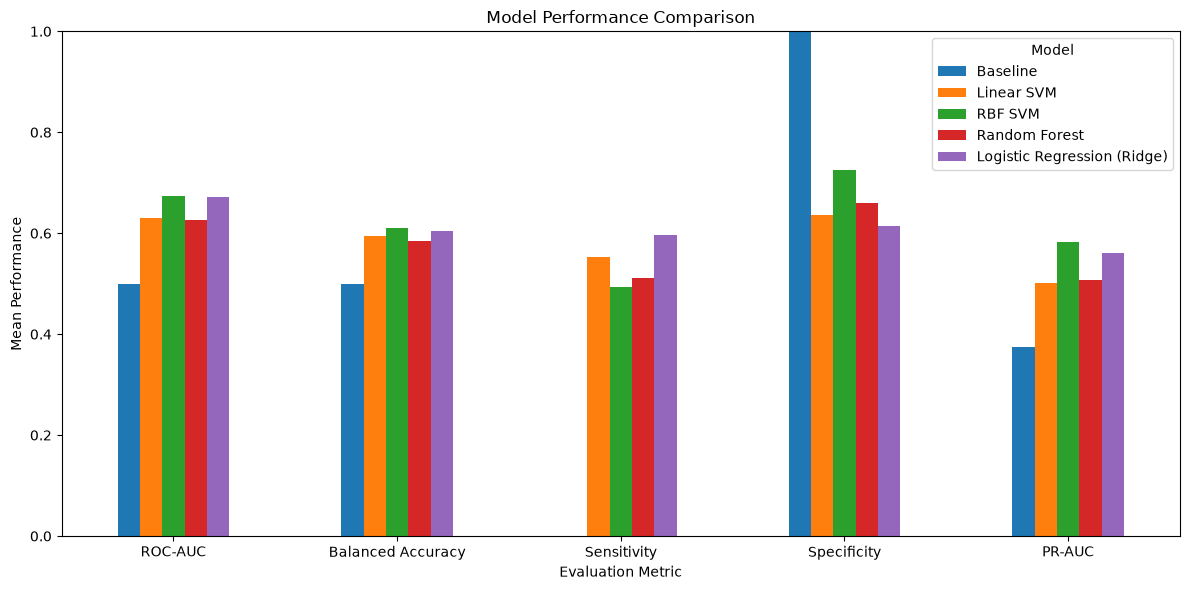

In [9]:

# Compare model performance

comparison = pd.DataFrame({
    "Baseline": {
        "ROC-AUC": baseline_df["ROC-AUC"].mean(),
        "Balanced Accuracy": baseline_df["Balanced Accuracy"].mean(),
        "Sensitivity": baseline_df["Sensitivity"].mean(),
        "Specificity": baseline_df["Specificity"].mean(),
        "PR-AUC": baseline_df["PR-AUC"].mean()
    },

    "Linear SVM": {
        "ROC-AUC": results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": results_df["Balanced Accuracy"].mean(),
        "Sensitivity": results_df["Sensitivity"].mean(),
        "Specificity": results_df["Specificity"].mean(),
        "PR-AUC": results_df["PR-AUC"].mean()
    },

    "RBF SVM": {
        "ROC-AUC": rbf_results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": rbf_results_df["Balanced Accuracy"].mean(),
        "Sensitivity": rbf_results_df["Sensitivity"].mean(),
        "Specificity": rbf_results_df["Specificity"].mean(),
        "PR-AUC": rbf_results_df["PR-AUC"].mean()
    },

    "Random Forest": {
        "ROC-AUC": rf_results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": rf_results_df["Balanced Accuracy"].mean(),
        "Sensitivity": rf_results_df["Sensitivity"].mean(),
        "Specificity": rf_results_df["Specificity"].mean(),
        "PR-AUC": rf_results_df["PR-AUC"].mean()
    },

    "Logistic Regression (Ridge)": {
        "ROC-AUC": elastic_net_results_df["ROC-AUC"].mean(),
        "Balanced Accuracy": elastic_net_results_df["Balanced Accuracy"].mean(),
        "Sensitivity": elastic_net_results_df["Sensitivity"].mean(),
        "Specificity": elastic_net_results_df["Specificity"].mean(),
        "PR-AUC": elastic_net_results_df["PR-AUC"].mean()
    }
})

display(comparison.round(3))

# Visualize model performance

comparison.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Mean Performance")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model")
plt.tight_layout()
plt.show()


### Model Comparison
The logistic regression and the RBF-SVM are the highest performers generally across the metrics, however, the logistic regression outperforms RBF SVM in sensitivity. This is a really important metric in this dataset because we want to pay special attention to the minority class, and we have very little tolerance for false negatives (we do not want to miss relapse cases). With that being said, the logistic regression sensitivity is 0.58, which is not much better than random chance. 
#### Next steps
It could be wise to revisit further normalization methods such as Quantile normalization. Alternatively, we could experiment with non-parametric feature selection methods such as mutual information.